## Change log for this revision - DELETE THIS CELL BEFORE SUBMISSION

Every line that was added or modified in this revision has a one-line marker
comment directly above it, of the form `# [EDIT n - NEW]` or
`# [EDIT n - CHANGED]`. Search the notebook for `[EDIT` to find them all.
Rewritten markdown cells open with an invisible `<!-- [EDIT n] ... -->` note.

| n | Change |
|---|---|
| 1 | Target-network refresh now counts optimizer steps, not environment steps (cell `51ad0aaa`). |
| 2 | Episode reward and predicted Q are plotted as the raw per-episode series with the 100-episode moving average overlaid; landing rate and thruster count stay moving-average only (cells `5ff04ef7`, `8b01e46e`, `8d7ab0e3`, `5424e7b8`). |
| 3 | Per-episode `base_reward` recorded and plotted, so the modified environment's shaped reward is not compared against the original environment's reward on the same axes (cells `6958e7ee`, `d17f9e52`, `d95ee5d3`). |
| 4 | Part (a) evidence: step-level action-replacement trace, binomial confidence interval instead of a fixed tolerance, and a near-miss counter (cell `ccea4aa9`). |
| 5 | `generate_discussion()` reduced to a numeric extractor; the (d) and (e) answer cells left as headings to be written by hand (cells `87cf18a8`, `37c34e16`, `ce89512d`). |
| 6 | `RUN_MODE` banner stating that it must be `"full"` for the final run (cell `5ed53ed9`). |
| 7 | Quoted the pip version constraint in the install cell, which was being read as a shell redirection (cell `23282018`). |

Run `python strip_edit_markers.py` in this folder to delete this cell and all
markers, then re-run the notebook in full mode for the final PDF.

# Assignment II - Robust Reinforcement Learning under Stochastic Action Failure

## Group 95 - Complete Solution Notebook

| Member | BITS ID | Planned contribution |
|---|---|---:|
| Ayan | `FILL_BEFORE_SUBMISSION` | 20% |
| Yash | `FILL_BEFORE_SUBMISSION` | 20% |
| Ravi | `FILL_BEFORE_SUBMISSION` | 20% |
| Sumanth | `FILL_BEFORE_SUBMISSION` | 20% |
| Vivek | `FILL_BEFORE_SUBMISSION` | 20% |

**Environment:** `LunarLander-v3`  
**Algorithms:** DQN and DDQN  
**Comparison:** Original environment versus modified environment with 15% stochastic thruster failure, fuel penalty, and safe-landing bonus.

> Before final submission, replace every placeholder, run the notebook in the BITS virtual lab, retain all outputs, add timestamped virtual-lab screenshots to the final PDF, and ensure the contribution declaration reflects the work actually performed.

## 0. Notebook execution modes

- `quick`: verifies that the complete pipeline runs; results are **not** suitable for final conclusions.
- `full`: intended for the final assignment experiment. It trains all four agents under identical settings.

The assignment requires the same seed, network architecture, optimizer, replay buffer, exploration strategy, hyperparameters, and training duration for all comparisons. The only algorithmic difference between DQN and DDQN below is the target Q-value computation.

In [1]:
# [EDIT 6 - NEW] Warning banner; the RUN_MODE value itself is unchanged.
# ---------------------------------------------------------------------------
# RUN_MODE MUST BE SET TO "full" FOR THE FINAL SUBMISSION RUN.
# "quick" trains only 8 short episodes; it exists to smoke-test the pipeline.
# Every plot, table and number produced in quick mode is a pipeline check and
# must not be read as an experimental result. Before submitting: set
# RUN_MODE = "full", restart the kernel, and run all cells top to bottom.
# ---------------------------------------------------------------------------
RUN_MODE = "quick"  # "quick" or "full"

# Installation command for a fresh BITS virtual-lab kernel.
# Run only when the packages are missing, then restart the kernel if required.
# %pip install "gymnasium[box2d]>=1.0.0" torch numpy pandas matplotlib

In [2]:
# Install necessary dependencies for LunarLander-v3
# [EDIT 7 - CHANGED] Was: %pip install gymnasium[box2d]>=1.0.0 ... (unquoted).
# The version constraint has to be quoted. Unquoted, the shell reads ">=1.0.0"
# as an output redirection: the constraint is silently dropped and the pip log
# is written to a file called "1.0.0" in this folder instead of being shown here.
%pip install swig
%pip install "gymnasium[box2d]>=1.0.0" torch numpy pandas matplotlib

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


## 1. Imports and reproducibility

The lecture workflow uses an online Q-network, an identical target network, experience replay, random mini-batches, epsilon-greedy exploration, loss-based backpropagation, and periodic copying of online-network weights into the target network. DDQN changes only how the next-state target is formed: the online network selects the action and the target network evaluates that selected action.

In [3]:
from __future__ import annotations

import copy
import json
import math
import os
import random
import time
from collections import deque
from dataclasses import asdict, dataclass
from pathlib import Path
from typing import Dict, Iterable, List, Optional, Tuple

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

SEED = 95
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
ARTIFACT_DIR = Path("group95_drl_artifacts")
ARTIFACT_DIR.mkdir(exist_ok=True)


def set_global_seed(seed: int) -> None:
    """Seed Python, NumPy, and PyTorch for repeatable comparisons."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
    # Determinism is useful for an academic comparison, although it can reduce speed.
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_global_seed(SEED)
print(f"Device: {DEVICE}")
# print(f"Run mode: {RUN_MODE}") # Removed as RUN_MODE is defined in a later cell

Device: cpu


## 2. Experiment configuration

The full configuration is deliberately shared by all four experiments. A hard target-network update is used, matching the DQN/DDQN workflow demonstrated in class. The validation states are collected once and kept unchanged throughout training.

In [4]:
# Ensure RUN_MODE is defined. It should typically be set in cell 5ed53ed9.
if 'RUN_MODE' not in globals():
    RUN_MODE = "quick" # Default if not set by the user in the prior cell.

@dataclass(frozen=True)
class Config:
    env_id: str = "LunarLander-v3"
    state_size: int = 8
    action_size: int = 4
    hidden_1: int = 128
    hidden_2: int = 128
    learning_rate: float = 5e-4
    gamma: float = 0.99
    batch_size: int = 64
    replay_capacity: int = 100_000
    min_replay_size: int = 1_000
    train_every_steps: int = 4
    target_update_steps: int = 1_000
    epsilon_start: float = 1.0
    epsilon_end: float = 0.01
    epsilon_decay_episodes: int = 800
    episodes: int = 1_500
    max_steps_per_episode: int = 1_000
    validation_state_count: int = 256
    evaluation_episodes: int = 100
    failure_probability: float = 0.15
    fuel_penalty: float = 0.3
    safe_landing_bonus: float = 50.0
    moving_average_window: int = 100
    log_every: int = 1
    checkpoint_every: int = 100


FULL_CONFIG = Config()
QUICK_CONFIG = Config(
    episodes=8,
    max_steps_per_episode=250,
    min_replay_size=128,
    replay_capacity=5_000,
    batch_size=32,
    validation_state_count=64,
    evaluation_episodes=5,
    epsilon_decay_episodes=20,
    target_update_steps=250,
    checkpoint_every=0,
)
CONFIG = FULL_CONFIG if RUN_MODE == "full" else QUICK_CONFIG
print(json.dumps(asdict(CONFIG), indent=2))

{
  "env_id": "LunarLander-v3",
  "state_size": 8,
  "action_size": 4,
  "hidden_1": 128,
  "hidden_2": 128,
  "learning_rate": 0.0005,
  "gamma": 0.99,
  "batch_size": 32,
  "replay_capacity": 5000,
  "min_replay_size": 128,
  "train_every_steps": 4,
  "target_update_steps": 250,
  "epsilon_start": 1.0,
  "epsilon_end": 0.01,
  "epsilon_decay_episodes": 20,
  "episodes": 8,
  "max_steps_per_episode": 250,
  "validation_state_count": 64,
  "evaluation_episodes": 5,
  "failure_probability": 0.15,
  "fuel_penalty": 0.3,
  "safe_landing_bonus": 50.0,
  "moving_average_window": 100,
  "log_every": 1,
  "checkpoint_every": 0
}


# Part (a) - Modified Environment Implementation and Verification (2.5 marks)

For an originally selected action $a$ and the action finally executed by the base environment $a_{exec}$:

- Action `0` is never replaced.
- Actions `1`, `2`, and `3` are independently replaced by `0` with probability `0.15`.
- The agent is not told whether replacement occurred.
- The modified reward is

$$R = R_{base} - 0.3\,\mathbf{1}(a \ne 0) + B,$$

where $B=50$ only for a safe terminal landing and is `0` otherwise. The fuel penalty uses the action **selected by the agent**, even when the thruster misfires.

In [5]:
def is_safe_landing(observation: np.ndarray, terminated: bool, truncated: bool) -> bool:
    """Return True only when every safe-landing condition in the assignment holds."""
    observation = np.asarray(observation, dtype=np.float32)
    return bool(
        terminated
        and not truncated
        and observation[6] == 1
        and observation[7] == 1
        and abs(float(observation[2])) < 0.10
        and abs(float(observation[3])) < 0.10
        and abs(float(observation[4])) < 0.10
    )


class StochasticActionFailureWrapper(gym.Wrapper):
    """LunarLander wrapper implementing the assignment's stochastic failure and reward rules.

    Important: no failure flag or reward-breakdown field is inserted into ``info``. Diagnostics
    are stored only as wrapper-side counters so the agent cannot observe the hidden failure.
    """

    def __init__(
        self,
        env: gym.Env,
        failure_probability: float = 0.15,
        fuel_penalty: float = 0.3,
        safe_landing_bonus: float = 50.0,
    ) -> None:
        super().__init__(env)
        if not 0.0 <= failure_probability <= 1.0:
            raise ValueError("failure_probability must be in [0, 1].")
        self.failure_probability = float(failure_probability)
        self.fuel_penalty = float(fuel_penalty)
        self.safe_landing_bonus = float(safe_landing_bonus)
        self._rng = np.random.default_rng()
        self.reset_diagnostics()

    def reset_diagnostics(self) -> None:
        """Reset experiment-side counters without changing the observation or action spaces."""
        self.total_steps = 0
        self.attempted_thruster_actions = 0
        self.failed_thruster_actions = 0
        self.total_fuel_penalty = 0.0
        self.total_landing_bonus = 0.0
        self.safe_landings = 0
        self.base_reward_sum = 0.0
        self.modified_reward_sum = 0.0

    def reset(self, *, seed: Optional[int] = None, options: Optional[dict] = None):
        # Re-seeding both the base environment and hidden failure generator makes runs reproducible.
        observation, info = self.env.reset(seed=seed, options=options)
        if seed is not None:
            self._rng = np.random.default_rng(seed)
        return observation, info

    def step(self, action: int):
        selected_action = int(action)
        if not self.action_space.contains(selected_action):
            raise ValueError(f"Invalid action: {selected_action}")

        executed_action = selected_action
        if selected_action in (1, 2, 3):
            self.attempted_thruster_actions += 1
            if self._rng.random() < self.failure_probability:
                executed_action = 0
                self.failed_thruster_actions += 1

        observation, base_reward, terminated, truncated, info = self.env.step(executed_action)

        penalty = self.fuel_penalty if selected_action != 0 else 0.0
        safe = is_safe_landing(observation, terminated, truncated)
        bonus = self.safe_landing_bonus if safe else 0.0
        modified_reward = float(base_reward) - penalty + bonus

        self.total_steps += 1
        self.total_fuel_penalty += penalty
        self.total_landing_bonus += bonus
        self.safe_landings += int(safe)
        self.base_reward_sum += float(base_reward)
        self.modified_reward_sum += modified_reward

        # Return the original info unchanged: the agent receives no failure indication.
        return observation, modified_reward, terminated, truncated, info

    def get_diagnostics(self) -> Dict[str, float]:
        """Return wrapper-side verification statistics; this is not exposed through ``info``."""
        attempted = self.attempted_thruster_actions
        empirical_failure_rate = (
            self.failed_thruster_actions / attempted if attempted > 0 else float("nan")
        )
        return {
            "total_steps": self.total_steps,
            "attempted_thruster_actions": attempted,
            "failed_thruster_actions": self.failed_thruster_actions,
            "empirical_failure_rate": empirical_failure_rate,
            "total_fuel_penalty": self.total_fuel_penalty,
            "expected_fuel_penalty": self.fuel_penalty * attempted,
            "safe_landings": self.safe_landings,
            "total_landing_bonus": self.total_landing_bonus,
            "base_reward_sum": self.base_reward_sum,
            "modified_reward_sum": self.modified_reward_sum,
        }

### 2.1 Environment factories

The original and modified environments share the same observation space, action space, termination rules, and base dynamics. Only the specified stochastic action replacement and reward calculation are added by the wrapper.

In [6]:
def make_environment(modified: bool, render_mode: Optional[str] = None) -> gym.Env:
    """Create the required original or modified LunarLander-v3 environment."""
    try:
        base_env = gym.make(CONFIG.env_id, render_mode=render_mode)
    except Exception as exc:
        raise RuntimeError(
            "Could not create LunarLander-v3. Install Gymnasium with Box2D support using "
            "`pip install gymnasium[box2d]` in the BITS virtual lab. Do not silently switch "
            "to another environment version for the final submission."
        ) from exc

    if not modified:
        return base_env
    return StochasticActionFailureWrapper(
        base_env,
        failure_probability=CONFIG.failure_probability,
        fuel_penalty=CONFIG.fuel_penalty,
        safe_landing_bonus=CONFIG.safe_landing_bonus,
    )

<!-- [EDIT 4] Cell rewritten to list the new verification evidence. -->
### 2.2 Random-policy verification

This experiment checks the empirical failure rate with a binomial confidence
interval, verifies that the fuel penalty is charged for **every attempted
thruster action** including misfires, prints a step-level trace of the
replacement rule, and counts near-miss landings for which the +50 bonus must be
withheld. Safe landings are rare under a random policy, so a deterministic unit
test follows in the next cell to check the reward boundaries exactly.

In [7]:
# [EDIT 4 - NEW] Three new helpers below; changes inside the verification function are marked separately.
def wilson_confidence_interval(
    successes: int, trials: int, z: float = 1.959963985
) -> Tuple[float, float]:
    """Return the Wilson score 95% confidence interval for a binomial proportion.

    A misfire is a Bernoulli trial with unknown probability p, so the observed
    failure rate is an estimate, not the parameter itself. The Wilson interval is
    used instead of a fixed tolerance because it scales with the sample size: a
    short quick-mode check produces a wide interval, and a long full-mode check
    produces a narrow one. The implementation avoids a SciPy dependency.
    """
    if trials == 0:
        return float("nan"), float("nan")
    proportion = successes / trials
    denominator = 1.0 + (z ** 2) / trials
    centre = proportion + (z ** 2) / (2 * trials)
    spread = z * math.sqrt(
        proportion * (1.0 - proportion) / trials + (z ** 2) / (4 * trials ** 2)
    )
    return (centre - spread) / denominator, (centre + spread) / denominator


class RecordingRandomGenerator:
    """Proxy around the wrapper's NumPy generator that remembers the last draw.

    The wrapper calls ``self._rng.random()`` exactly once per attempted thruster
    action. Temporarily substituting this proxy lets the verification report the
    random number r that decided each individual misfire, without changing a
    single line of the wrapper. Every other generator method is forwarded
    unchanged, so behaviour and the random stream are identical.
    """

    def __init__(self, generator: np.random.Generator) -> None:
        self._generator = generator
        self.last_draw: Optional[float] = None  # None until random() is called

    def random(self, *args, **kwargs):
        # Record the draw, then hand the identical value back to the wrapper.
        self.last_draw = float(self._generator.random(*args, **kwargs))
        return self.last_draw

    def __getattr__(self, name: str):
        # Everything else (integers, normal, ...) goes to the real generator.
        return getattr(self._generator, name)


def trace_action_replacement(steps: int = 20, seed: int = SEED) -> pd.DataFrame:
    """Record a step-level trace of the stochastic action-replacement rule.

    The table mirrors the worked example in the question: for each step it shows
    the action the policy selected, the random number drawn by the wrapper, the
    action the base environment actually executed, and the fuel penalty charged.
    The executed action and the penalty are read back from the wrapper's own
    counters rather than recomputed here, so the table is evidence about the
    wrapper instead of a restatement of the same logic.
    """
    env = make_environment(modified=True)
    env.reset(seed=seed)
    env.reset_diagnostics()

    # Install the recorder only after reset(), because reset(seed=...) rebuilds _rng.
    recorder = RecordingRandomGenerator(env._rng)
    env._rng = recorder

    action_rng = np.random.default_rng(seed)
    rows = []

    for step in range(1, steps + 1):
        selected_action = int(action_rng.integers(CONFIG.action_size))

        # Counter values before the step, so each row reports only its own effect.
        failed_before = env.failed_thruster_actions
        penalty_before = env.total_fuel_penalty
        recorder.last_draw = None  # a blank r means the wrapper drew no number

        _, _, terminated, truncated, _ = env.step(selected_action)

        # A misfire is identified by the wrapper's own failure counter increasing.
        misfired = env.failed_thruster_actions > failed_before
        rows.append(
            {
                "step": step,
                "selected_action a": selected_action,
                "random r": (
                    round(recorder.last_draw, 4)
                    if recorder.last_draw is not None
                    else np.nan
                ),
                "executed_action a_exec": 0 if misfired else selected_action,
                "penalty_applied": round(env.total_fuel_penalty - penalty_before, 2),
            }
        )

        if terminated or truncated:
            env.reset(seed=seed + step)
            # reset(seed=...) rebuilds _rng, so the recorder must be reinstalled.
            recorder = RecordingRandomGenerator(env._rng)
            env._rng = recorder

    env.close()
    return pd.DataFrame(rows)
# [EDIT 4 - NEW] End of the new helper block.


def verify_wrapper_with_random_policy(
    episodes: int = 100,
    max_steps: int = 1_000,
    seed: int = SEED,
) -> pd.DataFrame:
    # [EDIT 4 - NEW] Docstring added.
    """Run a random policy on the modified environment and check every part (a) claim.

    Returns a per-episode frame that also flags "near-miss" episodes: episodes
    that ended with both legs in contact but with a velocity or angle magnitude
    at or above 0.10, which is exactly the case in which the +50 bonus must be
    withheld.
    """
    env = make_environment(modified=True)
    assert isinstance(env, StochasticActionFailureWrapper)
    env.reset_diagnostics()

    episode_rows = []
    action_rng = np.random.default_rng(seed)

    for episode in range(episodes):
        observation, info = env.reset(seed=seed + episode)
        episode_reward = 0.0
        for step in range(max_steps):
            selected_action = int(action_rng.integers(CONFIG.action_size))
            observation, reward, terminated, truncated, info = env.step(selected_action)
            episode_reward += reward
            if terminated or truncated:
                break

        # [EDIT 4 - NEW] Terminal-state analysis and near-miss test.
        # Terminal-state quantities used by the safe-landing test.
        safe = is_safe_landing(observation, terminated, truncated)
        both_legs_down = bool(observation[6] == 1 and observation[7] == 1)
        worst_magnitude = float(
            max(abs(observation[2]), abs(observation[3]), abs(observation[4]))
        )
        # Near miss: touched down on both legs, but too fast or too tilted, so
        # the landing bonus must not have been awarded.
        near_miss = bool(
            terminated and not truncated and both_legs_down and not safe
        )

        episode_rows.append(
            {
                "episode": episode + 1,
                "reward": episode_reward,
                # [EDIT 4 - CHANGED] Reuses the safe-landing value computed above.
                "safe_landing": int(safe),
                # [EDIT 4 - NEW] Three near-miss diagnostic columns.
                "near_miss": int(near_miss),
                "both_legs_down": int(both_legs_down),
                "max_abs_velocity_or_angle": worst_magnitude,
                "steps": step + 1,
            }
        )

    diagnostics = env.get_diagnostics()
    env.close()
    # [EDIT 4 - NEW] Frame built here so the near-miss rows can be reported below.
    episode_frame = pd.DataFrame(episode_rows)

    print("Random-policy wrapper diagnostics")
    for key, value in diagnostics.items():
        print(f"{key:30s}: {value}")

    assert diagnostics["attempted_thruster_actions"] > 0

    # Claim 2: the fuel penalty is charged once for every selected thruster
    # action, whether or not the engine actually fired.
    assert np.isclose(
        diagnostics["total_fuel_penalty"],
        diagnostics["expected_fuel_penalty"],
        atol=1e-9,
    ), "Fuel penalty was not applied to every selected thruster action."

    # [EDIT 4 - CHANGED] Was: assert abs(empirical_rate - 0.15) < 0.03.
    # Claim 1: about 15% of attempted thruster actions are replaced. The test is
    # a 95% binomial confidence interval on the observed proportion, so the
    # sample size is taken into account instead of a fixed tolerance.
    failed = int(diagnostics["failed_thruster_actions"])
    attempted = int(diagnostics["attempted_thruster_actions"])
    empirical_rate = failed / attempted
    lower, upper = wilson_confidence_interval(failed, attempted)
    print(
        f"\nFailure rate: {failed}/{attempted} = {empirical_rate:.4f}\n"
        f"Wilson 95% confidence interval: [{lower:.4f}, {upper:.4f}]\n"
        f"Configured failure probability : {CONFIG.failure_probability:.4f}"
    )
    assert lower <= CONFIG.failure_probability <= upper, (
        f"The configured failure probability {CONFIG.failure_probability} lies outside "
        f"the 95% confidence interval [{lower:.4f}, {upper:.4f}] of the observed rate "
        f"{empirical_rate:.4f}. Re-run with more episodes before treating this as a bug: "
        "a 95% interval is expected to exclude the true value in 1 run out of 20."
    )

    # [EDIT 4 - NEW] Near-miss report and the withheld-bonus assertion.
    # Claim 3: the +50 bonus is awarded only on a strict safe landing. The total
    # bonus paid must equal 50 x (number of safe landings), so the near-miss
    # episodes counted below received nothing.
    near_misses = int(episode_frame["near_miss"].sum())
    assert np.isclose(
        diagnostics["total_landing_bonus"],
        CONFIG.safe_landing_bonus * diagnostics["safe_landings"],
        atol=1e-9,
    ), "Landing bonus was paid on an episode that was not a safe landing."
    print(
        f"\nSafe landings                   : {int(diagnostics['safe_landings'])}\n"
        f"Near misses (both legs down but  \n"
        f"  |velocity| or |angle| >= 0.10) : {near_misses}\n"
        f"Bonus paid on near misses        : "
        f"{diagnostics['total_landing_bonus'] - CONFIG.safe_landing_bonus * diagnostics['safe_landings']:.1f}"
    )
    if near_misses:
        print("\nNear-miss episodes (bonus withheld):")
        print(
            episode_frame.loc[episode_frame["near_miss"] == 1,
                              ["episode", "max_abs_velocity_or_angle", "reward"]]
            .to_string(index=False)
        )
    else:
        print(
            "\nNo near-miss episode occurred in this sample; a random policy rarely "
            "reaches the ground on both legs. The deterministic boundary test in the "
            "next cell covers the withheld-bonus case exactly."
        )
    # [EDIT 4 - NEW] End of the near-miss report.

    return episode_frame


# Use more episodes in the final run to make the empirical proportion more stable.
verification_episodes = 150 if RUN_MODE == "full" else 20
random_policy_verification = verify_wrapper_with_random_policy(episodes=verification_episodes)

# [EDIT 4 - CHANGED] Was: random_policy_verification.tail() as the cell result.
# Printed instead, so the trace tables below are the last thing shown.
print("\nLast verification episodes")
print(random_policy_verification.tail().to_string(index=False))

# [EDIT 4 - NEW] Everything below is the step-level evidence for part (a).
# Step-level evidence for the action-replacement rule, in the format used by the
# worked example in the question. NaN in the r column marks a step on which
# action 0 was selected: the wrapper draws no random number there, because
# action 0 is never replaced.
#
# Only about one thruster attempt in seven misfires, so the first 20 steps need
# not contain a replacement. A longer trace is therefore recorded and two views
# of it are printed: the first 20 steps in order, and the steps on which a
# replacement actually happened.
ACTION_REPLACEMENT_TRACE = trace_action_replacement(steps=500)

print("\nStep-level action-replacement trace (first 20 steps)")
print(ACTION_REPLACEMENT_TRACE.head(20).to_string(index=False))

# A replacement is visible as an executed action of 0 for a selected action of
# 1, 2 or 3; the fuel penalty column shows that it is charged all the same.
replaced_steps = ACTION_REPLACEMENT_TRACE[
    ACTION_REPLACEMENT_TRACE["executed_action a_exec"]
    != ACTION_REPLACEMENT_TRACE["selected_action a"]
]
print(
    f"\nReplaced (misfired) steps within the {len(ACTION_REPLACEMENT_TRACE)} traced steps: "
    f"{len(replaced_steps)}. Each has r < {CONFIG.failure_probability}, an executed "
    f"action of 0, and a fuel penalty of {CONFIG.fuel_penalty} charged anyway."
)
print(replaced_steps.head(8).to_string(index=False))

Random-policy wrapper diagnostics
total_steps                   : 1700
attempted_thruster_actions    : 1285
failed_thruster_actions       : 185
empirical_failure_rate        : 0.14396887159533073
total_fuel_penalty            : 385.50000000000887
expected_fuel_penalty         : 385.5
safe_landings                 : 3
total_landing_bonus           : 150.0
base_reward_sum               : -3483.2803293469046
modified_reward_sum           : -3718.7803293469055

Failure rate: 185/1285 = 0.1440
Wilson 95% confidence interval: [0.1258, 0.1642]
Configured failure probability : 0.1500

Safe landings                   : 3
Near misses (both legs down but  
  |velocity| or |angle| >= 0.10) : 3
Bonus paid on near misses        : 0.0

Near-miss episodes (bonus withheld):
 episode  max_abs_velocity_or_angle      reward
       3                   0.375336 -136.198164
       7                   0.911027  -99.085861
      10                   0.158241  -99.882052

Last verification episodes
 episode    

In [8]:
class OneStepLandingEnv(gym.Env):
    """Small deterministic test environment used only to validate reward-boundary logic."""

    metadata = {"render_modes": []}

    def __init__(self, safe: bool, base_reward: float = 10.0):
        super().__init__()
        self.safe = safe
        self.base_reward = float(base_reward)
        self.action_space = gym.spaces.Discrete(4)
        self.observation_space = gym.spaces.Box(
            low=-np.inf, high=np.inf, shape=(8,), dtype=np.float32
        )

    def reset(self, *, seed=None, options=None):
        super().reset(seed=seed)
        return np.zeros(8, dtype=np.float32), {}

    def step(self, action):
        observation = np.zeros(8, dtype=np.float32)
        if self.safe:
            observation[2] = 0.05
            observation[3] = -0.05
            observation[4] = 0.05
            observation[6] = 1.0
            observation[7] = 1.0
        else:
            observation[2] = 0.15  # violates the horizontal-velocity limit
            observation[6] = 1.0
            observation[7] = 1.0
        return observation, self.base_reward, True, False, {}


def verify_reward_boundary_conditions() -> None:
    # Failure probability is zero here so the test isolates reward calculation.
    safe_env = StochasticActionFailureWrapper(
        OneStepLandingEnv(safe=True), failure_probability=0.0
    )
    safe_env.reset(seed=SEED)
    _, safe_reward, terminated, truncated, info = safe_env.step(2)
    assert np.isclose(safe_reward, 10.0 - 0.3 + 50.0)
    assert info == {}, "The wrapper must not add diagnostic data to info."

    unsafe_env = StochasticActionFailureWrapper(
        OneStepLandingEnv(safe=False), failure_probability=0.0
    )
    unsafe_env.reset(seed=SEED)
    _, unsafe_reward, _, _, info = unsafe_env.step(2)
    assert np.isclose(unsafe_reward, 10.0 - 0.3)
    assert info == {}

    hold_env = StochasticActionFailureWrapper(
        OneStepLandingEnv(safe=False), failure_probability=0.0
    )
    hold_env.reset(seed=SEED)
    _, hold_reward, _, _, _ = hold_env.step(0)
    assert np.isclose(hold_reward, 10.0), "Do Nothing must not receive a fuel penalty."

    print("Reward boundary-condition tests passed.")


verify_reward_boundary_conditions()

Reward boundary-condition tests passed.


# Parts (b) and (c) - DQN and DDQN (8 marks)

## 3. Q-network

The state is the 8-dimensional LunarLander observation. The output contains four Q-values, one for each discrete action. The architecture is held fixed across DQN/DDQN and original/modified environments.

In [9]:
class QNetwork(nn.Module):
    """Fully connected function approximator for Q(s, a)."""

    def __init__(self, state_size: int, action_size: int, hidden_1: int, hidden_2: int):
        super().__init__()
        self.fc1 = nn.Linear(state_size, hidden_1)
        self.fc2 = nn.Linear(hidden_1, hidden_2)
        self.output = nn.Linear(hidden_2, action_size)

    def forward(self, state: torch.Tensor) -> torch.Tensor:
        x = F.relu(self.fc1(state))
        x = F.relu(self.fc2(x))
        return self.output(x)

## 4. Experience replay buffer

Transitions $(s,a,r,s',done)$ are stored and sampled uniformly at random. Random mini-batches reduce temporal correlation, as demonstrated in the webinar code.

In [10]:
class ReplayBuffer:
    """Fixed-size replay memory with uniform random mini-batch sampling."""

    def __init__(self, capacity: int, batch_size: int, seed: int):
        self.memory = deque(maxlen=capacity)
        self.batch_size = batch_size
        self.rng = random.Random(seed)

    def add(
        self,
        state: np.ndarray,
        action: int,
        reward: float,
        next_state: np.ndarray,
        done: bool,
    ) -> None:
        self.memory.append(
            (
                np.asarray(state, dtype=np.float32),
                int(action),
                float(reward),
                np.asarray(next_state, dtype=np.float32),
                bool(done),
            )
        )

    def sample(self):
        batch = self.rng.sample(self.memory, self.batch_size)
        states, actions, rewards, next_states, dones = zip(*batch)
        return (
            torch.as_tensor(np.asarray(states), dtype=torch.float32, device=DEVICE),
            torch.as_tensor(actions, dtype=torch.int64, device=DEVICE).unsqueeze(1),
            torch.as_tensor(rewards, dtype=torch.float32, device=DEVICE).unsqueeze(1),
            torch.as_tensor(np.asarray(next_states), dtype=torch.float32, device=DEVICE),
            torch.as_tensor(dones, dtype=torch.float32, device=DEVICE).unsqueeze(1),
        )

    def __len__(self) -> int:
        return len(self.memory)

## 5. Unified DQN/DDQN agent

The `double_dqn` flag changes exactly one operation:

### DQN target
$$y=r+\gamma(1-d)\max_{a'}Q_{target}(s',a')$$

### DDQN target
$$a^*=\arg\max_{a'}Q_{online}(s',a'),\qquad
 y=r+\gamma(1-d)Q_{target}(s',a^*)$$

All remaining code, architecture, optimizer, replay buffer, epsilon schedule, seed, and duration are identical.

In [11]:
class DQNAgent:
    """One implementation used for both DQN and DDQN; only the target rule differs."""

    def __init__(self, config: Config, double_dqn: bool, seed: int):
        set_global_seed(seed)
        self.config = config
        self.double_dqn = bool(double_dqn)
        self.action_rng = np.random.default_rng(seed)

        self.online_network = QNetwork(
            config.state_size,
            config.action_size,
            config.hidden_1,
            config.hidden_2,
        ).to(DEVICE)
        self.target_network = QNetwork(
            config.state_size,
            config.action_size,
            config.hidden_1,
            config.hidden_2,
        ).to(DEVICE)
        self.target_network.load_state_dict(self.online_network.state_dict())
        self.target_network.eval()

        self.optimizer = optim.Adam(
            self.online_network.parameters(), lr=config.learning_rate
        )
        self.loss_function = nn.MSELoss()
        self.replay_buffer = ReplayBuffer(
            config.replay_capacity, config.batch_size, seed
        )
        self.environment_steps = 0
        self.optimization_steps = 0

        # [EDIT 1 - NEW] Refresh period, expressed in optimisation steps.
        # One optimisation step happens every ``train_every_steps`` environment
        # steps, so refreshing the target network every ``target_update_steps``
        # environment steps means refreshing it every this-many optimisation
        # steps. The period is stored once so the update rule below can be a
        # plain counter test on the number of optimiser updates.
        self.target_update_period = max(
            1, config.target_update_steps // config.train_every_steps
        )

    def epsilon_for_episode(self, episode_index: int) -> float:
        """Exponential epsilon decay from epsilon_start to epsilon_end."""
        fraction = min(1.0, episode_index / max(1, self.config.epsilon_decay_episodes))
        return self.config.epsilon_end + (
            self.config.epsilon_start - self.config.epsilon_end
        ) * math.exp(-5.0 * fraction)

    def act(self, state: np.ndarray, epsilon: float) -> int:
        """Select an epsilon-greedy action using an agent-owned reproducible RNG."""
        if self.action_rng.random() < epsilon:
            return int(self.action_rng.integers(self.config.action_size))
        state_tensor = torch.as_tensor(
            state, dtype=torch.float32, device=DEVICE
        ).unsqueeze(0)
        with torch.no_grad():
            return int(self.online_network(state_tensor).argmax(dim=1).item())

    def store_transition(self, state, action, reward, next_state, done) -> None:
        self.replay_buffer.add(state, action, reward, next_state, done)

    def learn_if_ready(self) -> Optional[float]:
        """Perform one update when replay warm-up and update-frequency conditions hold."""
        self.environment_steps += 1
        if len(self.replay_buffer) < self.config.min_replay_size:
            return None
        if self.environment_steps % self.config.train_every_steps != 0:
            return None

        states, actions, rewards, next_states, dones = self.replay_buffer.sample()
        predicted_q = self.online_network(states).gather(1, actions)

        with torch.no_grad():
            if self.double_dqn:
                # DDQN: online network selects; target network evaluates.
                next_actions = self.online_network(next_states).argmax(
                    dim=1, keepdim=True
                )
                next_q = self.target_network(next_states).gather(1, next_actions)
            else:
                # DQN: target network performs both maximisation and evaluation.
                next_q = self.target_network(next_states).max(
                    dim=1, keepdim=True
                ).values

            target_q = rewards + self.config.gamma * next_q * (1.0 - dones)

        loss = self.loss_function(predicted_q, target_q)
        self.optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(self.online_network.parameters(), max_norm=10.0)
        self.optimizer.step()
        self.optimization_steps += 1

        # [EDIT 1 - CHANGED] Was: if self.environment_steps % target_update_steps == 0.
        # Count optimisation steps, not environment steps. This line is reached
        # only on an environment step that is a multiple of train_every_steps,
        # so testing environment_steps against target_update_steps here would
        # only ever fire on their lowest common multiple and the target network
        # would be refreshed far less often than the configuration states.
        if self.optimization_steps % self.target_update_period == 0:
            self.target_network.load_state_dict(self.online_network.state_dict())

        return float(loss.item())

    def average_validation_q(self, validation_states: np.ndarray) -> float:
        """Mean maximum predicted Q-value over the unchanged validation state set."""
        states = torch.as_tensor(
            validation_states, dtype=torch.float32, device=DEVICE
        )
        with torch.no_grad():
            values = self.online_network(states).max(dim=1).values
        return float(values.mean().item())

    def save(self, path: Path) -> None:
        # [EDIT 1 - NEW] Docstring added.
        """Write network, optimizer, configuration and step counters to disk."""
        torch.save(
            {
                "double_dqn": self.double_dqn,
                "config": asdict(self.config),
                "online_state_dict": self.online_network.state_dict(),
                "target_state_dict": self.target_network.state_dict(),
                "optimizer_state_dict": self.optimizer.state_dict(),
                "environment_steps": self.environment_steps,
                "optimization_steps": self.optimization_steps,
                # [EDIT 1 - NEW] Saved so the refresh cadence stays auditable.
                "target_update_period": self.target_update_period,
            },
            path,
        )

## 6. Fixed validation states

The Q-value plot must use a fixed validation set that does not change during training. The following function collects that set once, saves it, and reuses the exact same array for all four agents.

In [12]:
def collect_fixed_validation_states(
    count: int, seed: int = SEED
) -> np.ndarray:
    env = make_environment(modified=False)
    rng = np.random.default_rng(seed)
    states: List[np.ndarray] = []
    state, _ = env.reset(seed=seed)

    while len(states) < count:
        states.append(np.asarray(state, dtype=np.float32).copy())
        action = int(rng.integers(CONFIG.action_size))
        state, _, terminated, truncated, _ = env.step(action)
        if terminated or truncated:
            state, _ = env.reset(seed=seed + len(states))

    env.close()
    validation_states = np.asarray(states, dtype=np.float32)
    np.save(ARTIFACT_DIR / "fixed_validation_states.npy", validation_states)
    return validation_states


FIXED_VALIDATION_STATES = collect_fixed_validation_states(
    CONFIG.validation_state_count
)
print("Fixed validation-state shape:", FIXED_VALIDATION_STATES.shape)
print("Validation checksum:", float(FIXED_VALIDATION_STATES.sum()))

Fixed validation-state shape: (64, 8)
Validation checksum: 72.95317077636719


<!-- [EDIT 3] List updated: base environment reward added as item 2. -->
## 7. Training loop and per-episode measurements

For each episode the notebook records:

1. total episode reward (as seen by the agent, including the penalty and bonus
   in the modified environment);
2. base environment reward, that is the untouched LunarLander reward, which is
   the only reward on a common scale across the original and modified runs;
3. mean predicted Q-value on the unchanged validation set;
4. safe-landing indicator and its 100-episode moving average;
5. number of agent-selected thruster actions (`1`, `2`, or `3`);
6. episode length, epsilon, mean loss, and wall-clock time.

In [13]:
def train_agent(
    run_name: str,
    double_dqn: bool,
    modified_environment: bool,
    config: Config,
    validation_states: np.ndarray,
    seed: int = SEED,
) -> Tuple[DQNAgent, pd.DataFrame]:
    # [EDIT 3 - NEW] Docstring added.
    """Train one agent and return it together with its per-episode history frame."""
    set_global_seed(seed)
    env = make_environment(modified=modified_environment)
    agent = DQNAgent(config=config, double_dqn=double_dqn, seed=seed)
    history_rows: List[dict] = []

    # [EDIT 3 - CHANGED] Was: an inline isinstance check used only once here.
    # The modified environment's episode reward contains the -0.3 per-step fuel
    # penalty and the +50 bonus, so it is on a different scale from the original
    # environment's reward. The wrapper accumulates the untouched LunarLander
    # reward in base_reward_sum, and the per-episode difference of that counter
    # gives a reward that is directly comparable across all four runs.
    uses_wrapper = isinstance(env, StochasticActionFailureWrapper)
    if uses_wrapper:
        env.reset_diagnostics()

    run_start = time.time()
    for episode_index in range(config.episodes):
        state, info = env.reset(seed=seed + episode_index)
        epsilon = agent.epsilon_for_episode(episode_index)
        episode_reward = 0.0
        episode_losses: List[float] = []
        selected_thrusters = 0
        terminated = truncated = False
        final_observation = np.asarray(state, dtype=np.float32)
        episode_start = time.time()
        # [EDIT 3 - NEW] Counter value before the episode starts.
        # Taking the difference at the end isolates this episode's base reward.
        base_reward_before = env.base_reward_sum if uses_wrapper else 0.0

        for step_index in range(config.max_steps_per_episode):
            action = agent.act(state, epsilon)
            selected_thrusters += int(action in (1, 2, 3))

            next_state, reward, terminated, truncated, info = env.step(action)
            done = terminated or truncated
            agent.store_transition(state, action, reward, next_state, done)
            loss = agent.learn_if_ready()
            if loss is not None:
                episode_losses.append(loss)

            episode_reward += float(reward)
            state = next_state
            final_observation = np.asarray(next_state, dtype=np.float32)
            if done:
                break

        safe_landing = int(
            is_safe_landing(final_observation, terminated, truncated)
        )
        average_q = agent.average_validation_q(validation_states)
        # [EDIT 3 - NEW] Per-episode base reward.
        # In the original environment no penalty or bonus is added, so the base
        # reward and the episode reward are the same quantity there.
        base_reward = (
            env.base_reward_sum - base_reward_before if uses_wrapper else episode_reward
        )

        row = {
            "run": run_name,
            "episode": episode_index + 1,
            "episode_reward": episode_reward,
            # [EDIT 3 - NEW] New history column, on the common reward scale.
            "base_reward": base_reward,
            "average_predicted_q": average_q,
            "safe_landing": safe_landing,
            "thruster_activations": selected_thrusters,
            "steps": step_index + 1,
            "epsilon": epsilon,
            "mean_loss": float(np.mean(episode_losses)) if episode_losses else np.nan,
            "episode_seconds": time.time() - episode_start,
        }

        # [EDIT 3 - CHANGED] Was: isinstance(env, StochasticActionFailureWrapper).
        if uses_wrapper:
            diagnostics = env.get_diagnostics()
            row["cumulative_attempted_thrusters"] = diagnostics[
                "attempted_thruster_actions"
            ]
            row["cumulative_failed_thrusters"] = diagnostics[
                "failed_thruster_actions"
            ]
            row["cumulative_failure_rate"] = diagnostics[
                "empirical_failure_rate"
            ]
        history_rows.append(row)

        if config.log_every and (episode_index + 1) % config.log_every == 0:
            recent = pd.DataFrame(history_rows[-min(100, len(history_rows)):])
            # [EDIT 3 - CHANGED] Progress line now also prints the base reward.
            print(
                f"{run_name:14s} | ep {episode_index + 1:4d}/{config.episodes} | "
                f"reward {episode_reward:8.2f} | base {base_reward:8.2f} | "
                f"avg100 {recent.episode_reward.mean():8.2f} | "
                f"safe100 {recent.safe_landing.mean():5.2%} | Q {average_q:8.3f} | "
                f"eps {epsilon:5.3f} | steps {step_index + 1:4d}"
            )

        if (
            config.checkpoint_every
            and (episode_index + 1) % config.checkpoint_every == 0
        ):
            agent.save(ARTIFACT_DIR / f"{run_name}_episode_{episode_index + 1}.pt")
            pd.DataFrame(history_rows).to_csv(
                ARTIFACT_DIR / f"{run_name}_history_partial.csv", index=False
            )

    history = pd.DataFrame(history_rows)
    # Moving averages over the previous 100 episodes, used by the plots.
    history["landing_rate_ma100"] = history["safe_landing"].rolling(
        config.moving_average_window, min_periods=1
    ).mean()
    history["reward_ma100"] = history["episode_reward"].rolling(
        config.moving_average_window, min_periods=1
    ).mean()
    # [EDIT 3 - NEW] Moving average of the new base-reward column.
    history["base_reward_ma100"] = history["base_reward"].rolling(
        config.moving_average_window, min_periods=1
    ).mean()
    history["q_ma100"] = history["average_predicted_q"].rolling(
        config.moving_average_window, min_periods=1
    ).mean()
    history["thrusters_ma100"] = history["thruster_activations"].rolling(
        config.moving_average_window, min_periods=1
    ).mean()
    history.to_csv(ARTIFACT_DIR / f"{run_name}_history.csv", index=False)
    agent.save(ARTIFACT_DIR / f"{run_name}_final.pt")
    print(f"Completed {run_name} in {(time.time() - run_start) / 60:.2f} minutes.")
    env.close()
    return agent, history

## 8. Train the four required agents

The four runs use the exact same `CONFIG`, seed, network class, optimizer, loss, replay settings, epsilon schedule, validation states, and number of episodes. The environment flag and DQN/DDQN target rule are the only intended differences.

> A full run can take substantial time. Use the BITS virtual lab, prevent the session from sleeping, and keep the generated checkpoints and CSV files.

In [14]:
RUN_SPECS = {
    "DQN_Original": {"double_dqn": False, "modified_environment": False},
    "DDQN_Original": {"double_dqn": True, "modified_environment": False},
    "DQN_Modified": {"double_dqn": False, "modified_environment": True},
    "DDQN_Modified": {"double_dqn": True, "modified_environment": True},
}

trained_agents: Dict[str, DQNAgent] = {}
histories: Dict[str, pd.DataFrame] = {}

for run_name, spec in RUN_SPECS.items():
    print("\n" + "=" * 90)
    print("Starting", run_name)
    agent, history = train_agent(
        run_name=run_name,
        double_dqn=spec["double_dqn"],
        modified_environment=spec["modified_environment"],
        config=CONFIG,
        validation_states=FIXED_VALIDATION_STATES,
        seed=SEED,
    )
    trained_agents[run_name] = agent
    histories[run_name] = history


Starting DQN_Original


DQN_Original   | ep    1/8 | reward  -127.61 | base  -127.61 | avg100  -127.61 | safe100 0.00% | Q    0.139 | eps 1.000 | steps  112
DQN_Original   | ep    2/8 | reward  -234.74 | base  -234.74 | avg100  -181.17 | safe100 0.00% | Q    0.155 | eps 0.781 | steps   85
DQN_Original   | ep    3/8 | reward  -534.15 | base  -534.15 | avg100  -298.83 | safe100 0.00% | Q    0.015 | eps 0.610 | steps  112


DQN_Original   | ep    4/8 | reward  -379.43 | base  -379.43 | avg100  -318.98 | safe100 0.00% | Q   -0.418 | eps 0.478 | steps   68
DQN_Original   | ep    5/8 | reward  -279.14 | base  -279.14 | avg100  -311.01 | safe100 0.00% | Q   -1.234 | eps 0.374 | steps   86
DQN_Original   | ep    6/8 | reward  -125.83 | base  -125.83 | avg100  -280.15 | safe100 0.00% | Q   -1.835 | eps 0.294 | steps   76


DQN_Original   | ep    7/8 | reward    25.74 | base    25.74 | avg100  -236.45 | safe100 0.00% | Q   -2.235 | eps 0.231 | steps  250
DQN_Original   | ep    8/8 | reward  -128.78 | base  -128.78 | avg100  -222.99 | safe100 0.00% | Q   -2.215 | eps 0.182 | steps  159
Completed DQN_Original in 0.01 minutes.

Starting DDQN_Original
DDQN_Original  | ep    1/8 | reward  -127.61 | base  -127.61 | avg100  -127.61 | safe100 0.00% | Q    0.139 | eps 1.000 | steps  112


DDQN_Original  | ep    2/8 | reward  -234.74 | base  -234.74 | avg100  -181.17 | safe100 0.00% | Q    0.144 | eps 0.781 | steps   85
DDQN_Original  | ep    3/8 | reward  -535.78 | base  -535.78 | avg100  -299.37 | safe100 0.00% | Q   -0.034 | eps 0.610 | steps  113
DDQN_Original  | ep    4/8 | reward  -380.49 | base  -380.49 | avg100  -319.65 | safe100 0.00% | Q   -0.468 | eps 0.478 | steps   67


DDQN_Original  | ep    5/8 | reward  -417.43 | base  -417.43 | avg100  -339.21 | safe100 0.00% | Q   -1.206 | eps 0.374 | steps   84
DDQN_Original  | ep    6/8 | reward  -483.79 | base  -483.79 | avg100  -363.30 | safe100 0.00% | Q   -1.935 | eps 0.294 | steps  102
DDQN_Original  | ep    7/8 | reward  -217.62 | base  -217.62 | avg100  -342.49 | safe100 0.00% | Q   -1.926 | eps 0.231 | steps   54


... (2 outputs left out)

DQN_Modified   | ep    7/8 | reward  -261.81 | base  -195.81 | avg100  -276.53 | safe100 0.00% | Q   -2.806 | eps 0.231 | steps  239
DQN_Modified   | ep    8/8 | reward  -370.83 | base  -348.93 | avg100  -288.31 | safe100 0.00% | Q   -3.199 | eps 0.182 | steps  109
Completed DQN_Modified in 0.01 minutes.

Starting DDQN_Modified
DDQN_Modified  | ep    1/8 | reward  -152.70 | base  -129.90 | avg100  -152.70 | safe100 0.00% | Q    0.139 | eps 1.000 | steps  106
DDQN_Modified  | ep    2/8 | reward  -323.35 | base  -305.35 | avg100  -238.03 | safe100 0.00% | Q   -0.055 | eps 0.781 | steps   78


DDQN_Modified  | ep    3/8 | reward  -387.68 | base  -355.58 | avg100  -287.91 | safe100 0.00% | Q   -0.546 | eps 0.610 | steps  117
DDQN_Modified  | ep    4/8 | reward  -277.45 | base  -258.25 | avg100  -285.29 | safe100 0.00% | Q   -1.044 | eps 0.478 | steps   83
DDQN_Modified  | ep    5/8 | reward  -411.75 | base  -394.35 | avg100  -310.59 | safe100 0.00% | Q   -1.740 | eps 0.374 | steps   65


DDQN_Modified  | ep    6/8 | reward  -501.29 | base  -487.79 | avg100  -342.37 | safe100 0.00% | Q   -2.709 | eps 0.294 | steps   77
DDQN_Modified  | ep    7/8 | reward  -363.83 | base  -315.83 | avg100  -345.43 | safe100 0.00% | Q   -2.607 | eps 0.231 | steps  172


DDQN_Modified  | ep    8/8 | reward  -333.63 | base  -303.93 | avg100  -343.96 | safe100 0.00% | Q   -4.014 | eps 0.182 | steps  104
Completed DDQN_Modified in 0.01 minutes.


# Part (d) - Performance Evaluation (2 marks)

## 9. Greedy evaluation

Training curves can contain exploration noise. The following evaluation uses `epsilon=0` and separately reports average reward, safe-landing rate, and average selected thruster activations.

In [15]:
def evaluate_greedy_policy(
    agent: DQNAgent,
    modified_environment: bool,
    episodes: int,
    seed: int = SEED + 10_000,
) -> Dict[str, float]:
    env = make_environment(modified=modified_environment)
    rewards: List[float] = []
    safe_landings: List[int] = []
    thrusters: List[int] = []

    for episode in range(episodes):
        state, info = env.reset(seed=seed + episode)
        episode_reward = 0.0
        selected_thrusters = 0
        terminated = truncated = False
        final_observation = np.asarray(state, dtype=np.float32)

        for _ in range(CONFIG.max_steps_per_episode):
            action = agent.act(state, epsilon=0.0)
            selected_thrusters += int(action in (1, 2, 3))
            state, reward, terminated, truncated, info = env.step(action)
            episode_reward += float(reward)
            final_observation = np.asarray(state, dtype=np.float32)
            if terminated or truncated:
                break

        rewards.append(episode_reward)
        safe_landings.append(
            int(is_safe_landing(final_observation, terminated, truncated))
        )
        thrusters.append(selected_thrusters)

    env.close()
    return {
        "evaluation_reward_mean": float(np.mean(rewards)),
        "evaluation_reward_std": float(np.std(rewards)),
        "evaluation_safe_landing_rate": float(np.mean(safe_landings)),
        "evaluation_thrusters_mean": float(np.mean(thrusters)),
    }


evaluation_rows = []
for run_name, spec in RUN_SPECS.items():
    result = evaluate_greedy_policy(
        trained_agents[run_name],
        modified_environment=spec["modified_environment"],
        episodes=CONFIG.evaluation_episodes,
    )
    evaluation_rows.append({"run": run_name, **result})

EVALUATION_SUMMARY = pd.DataFrame(evaluation_rows).set_index("run")
EVALUATION_SUMMARY.to_csv(ARTIFACT_DIR / "greedy_evaluation_summary.csv")
EVALUATION_SUMMARY

,evaluation_reward_mean,evaluation_reward_std,evaluation_safe_landing_rate,evaluation_thrusters_mean
run,,,,
DQN_Original,-224.915261,67.636202,0.0,37.0
DDQN_Original,-155.538738,32.396969,0.0,4.6
DQN_Modified,-515.071182,484.506331,0.0,90.0
DDQN_Modified,-650.386261,371.752822,0.0,123.6


<!-- [EDIT 2] Cell rewritten to state which plots show the raw per-episode series. -->
## 10. Required plots

Episode reward, base reward and predicted Q-value are drawn as the raw
per-episode series (faint, alpha 0.25) with the 100-episode moving average
overlaid, so the actual measurement and its trend are both visible. The
successful-landing rate and the thruster count are drawn as the 100-episode
moving average only, as the assignment specifies for the landing rate. Every
figure is saved at publication quality.

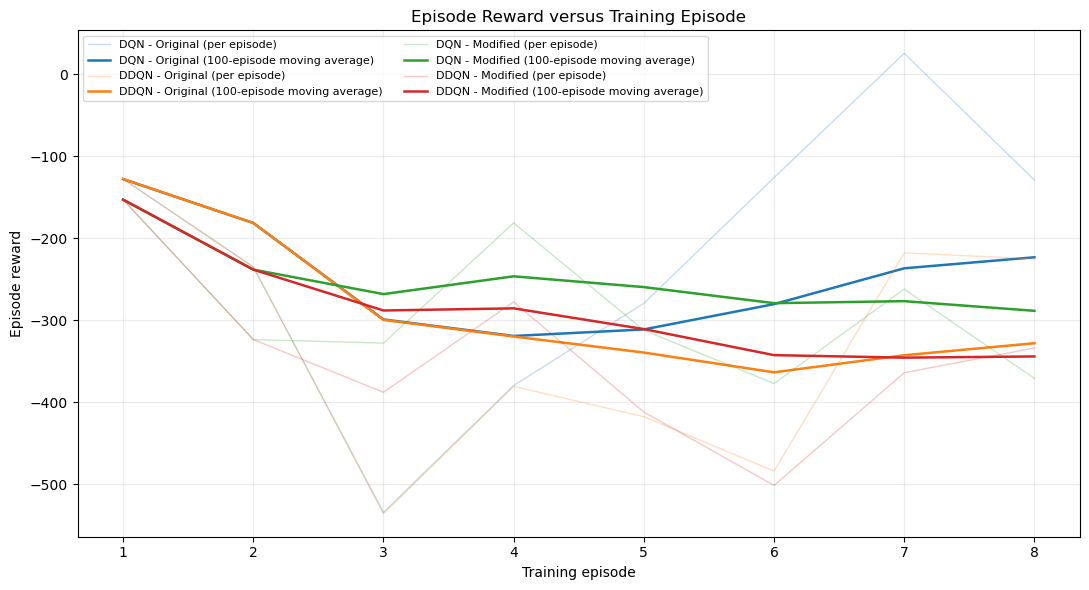

Saved: group95_drl_artifacts\01_episode_reward.png


In [16]:
PLOT_LABELS = {
    "DQN_Original": "DQN - Original",
    "DDQN_Original": "DDQN - Original",
    "DQN_Modified": "DQN - Modified",
    "DDQN_Modified": "DDQN - Modified",
}

# [EDIT 2 - CHANGED] Was: a local dict inside plot_metric. [EDIT 3 - NEW] base_reward.
# Moving-average column that belongs to each raw per-episode column.
MOVING_AVERAGE_COLUMNS = {
    "episode_reward": "reward_ma100",
    "base_reward": "base_reward_ma100",
    "average_predicted_q": "q_ma100",
    "safe_landing": "landing_rate_ma100",
    "thruster_activations": "thrusters_ma100",
}


def plot_metric(
    column: str,
    ylabel: str,
    title: str,
    filename: str,
    # [EDIT 2 - CHANGED] Was: a single use_moving_average flag.
    show_raw_series: bool = False,
    show_moving_average: bool = True,
) -> None:
    # [EDIT 2 - NEW] Docstring added.
    """Plot one metric for all four runs and save it at publication quality.

    show_raw_series
        Draw the faint per-episode measurement (alpha 0.25) behind the curve.
        Used for episode reward, base reward and predicted Q-value, where the
        assignment asks for the value versus training episode and the moving
        average is only a reading aid over a noisy series.
    show_moving_average
        Draw the 100-episode moving average. This is the required form for the
        landing rate, and is drawn on top of the raw series for the others.
    """
    plt.figure(figsize=(11, 6))
    # [EDIT 2 - NEW] Explicit colour cycle.
    # One fixed colour per run, so a faint raw series and its moving average are
    # visually paired and the four runs stay distinguishable.
    colours = plt.rcParams["axes.prop_cycle"].by_key()["color"]

    for run_index, (run_name, history) in enumerate(histories.items()):
        colour = colours[run_index % len(colours)]

        # [EDIT 2 - NEW] Faint per-episode series drawn behind the average.
        if show_raw_series:
            plt.plot(
                history["episode"],
                history[column],
                color=colour,
                alpha=0.25,
                linewidth=1.0,
                label=f"{PLOT_LABELS[run_name]} (per episode)",
            )

        # [EDIT 2 - CHANGED] Moving average is now optional and drawn on top.
        if show_moving_average:
            plt.plot(
                history["episode"],
                history[MOVING_AVERAGE_COLUMNS[column]],
                color=colour,
                linewidth=1.8,
                label=(
                    f"{PLOT_LABELS[run_name]} (100-episode moving average)"
                    if show_raw_series
                    else PLOT_LABELS[run_name]
                ),
            )

    plt.xlabel("Training episode")
    plt.ylabel(ylabel)
    plt.title(title)
    # [EDIT 2 - CHANGED] Two-column legend when eight lines are drawn.
    plt.legend(fontsize=8, ncol=2 if show_raw_series else 1)
    plt.grid(alpha=0.25)
    plt.tight_layout()
    path = ARTIFACT_DIR / filename
    plt.savefig(path, dpi=220, bbox_inches="tight")
    plt.show()
    print("Saved:", path)


# [EDIT 2 - CHANGED] Was: use_moving_average=True, and a moving-average y-label.
# Both series are shown now, so the label names the quantity itself.
plot_metric(
    "episode_reward",
    "Episode reward",
    "Episode Reward versus Training Episode",
    "01_episode_reward.png",
    show_raw_series=True,
)

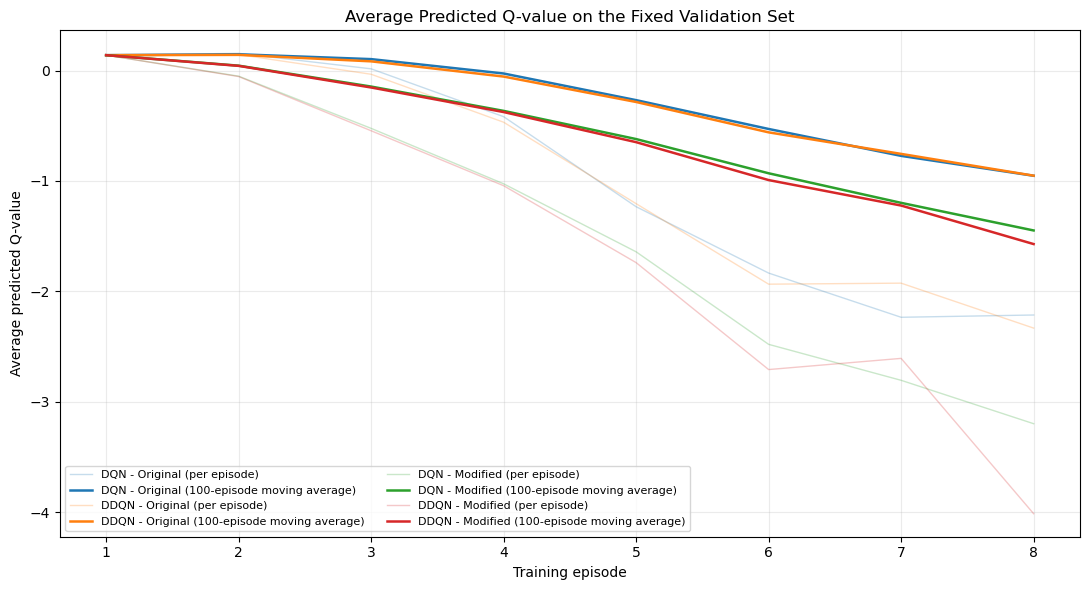

Saved: group95_drl_artifacts\02_average_predicted_q.png


In [17]:
# [EDIT 2 - CHANGED] Was: use_moving_average=True, and a moving-average y-label.
plot_metric(
    "average_predicted_q",
    "Average predicted Q-value",
    "Average Predicted Q-value on the Fixed Validation Set",
    "02_average_predicted_q.png",
    show_raw_series=True,
)

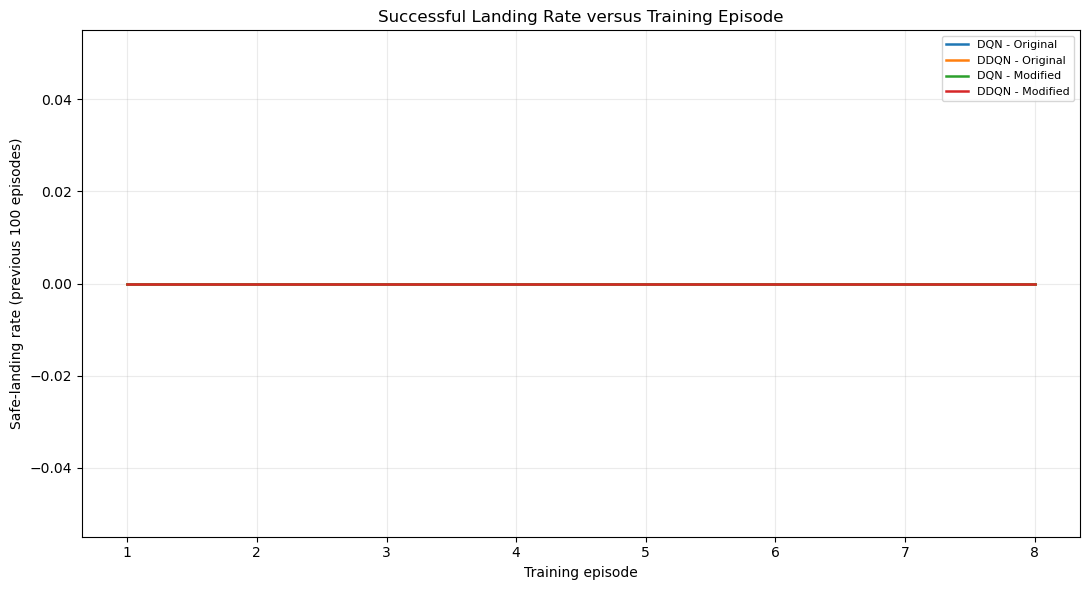

Saved: group95_drl_artifacts\03_safe_landing_rate.png


In [18]:
# [EDIT 2 - CHANGED] Was: use_moving_average=True; now the default.
# The assignment asks for the landing rate as a moving average over the previous
# 100 episodes, so no raw per-episode 0/1 series is drawn here.
plot_metric(
    "safe_landing",
    "Safe-landing rate (previous 100 episodes)",
    "Successful Landing Rate versus Training Episode",
    "03_safe_landing_rate.png",
)

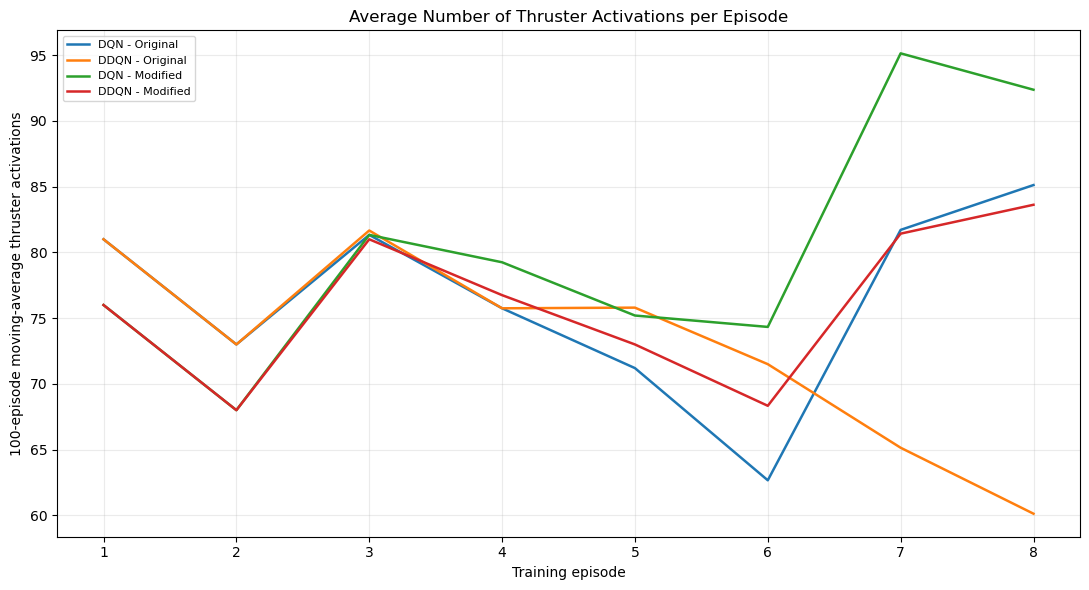

Saved: group95_drl_artifacts\04_thruster_activations.png


In [19]:
# [EDIT 2 - CHANGED] Was: use_moving_average=True; now the default.
plot_metric(
    "thruster_activations",
    "100-episode moving-average thruster activations",
    "Average Number of Thruster Activations per Episode",
    "04_thruster_activations.png",
)

<!-- [EDIT 3] Whole cell is new. -->
### 10.1 Reward on a common scale

The modified environment's episode reward is not comparable with the original
environment's episode reward: it also contains a -0.3 fuel penalty on every
step on which a thruster was selected, and a +50 bonus on a safe landing. Two
agents with identical flight behaviour would therefore still show different
curves in plot 01. The plot below removes that confound by using `base_reward`,
the untouched LunarLander reward recorded by the wrapper, which is identical to
`episode_reward` for the two original-environment runs.

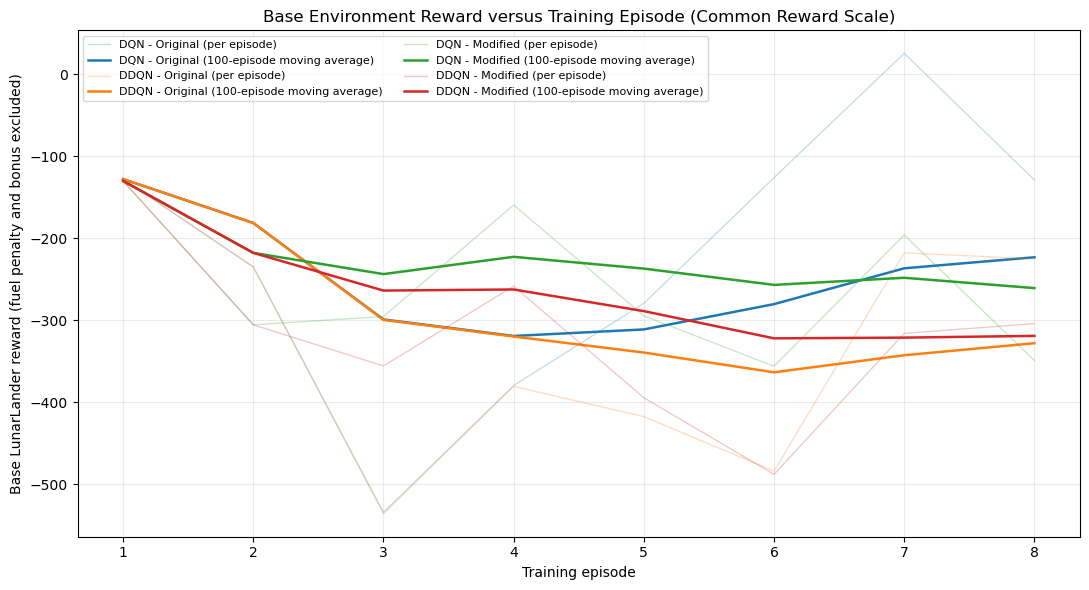

Saved: group95_drl_artifacts\05_base_environment_reward.png


In [20]:
# [EDIT 3 - NEW] Whole cell is new: the fifth plot.
# Common-scale comparison: the shaping terms (-0.3 per thruster step, +50 on a
# safe landing) are excluded, so all four runs are measured by the same rule.
plot_metric(
    "base_reward",
    "Base LunarLander reward (fuel penalty and bonus excluded)",
    "Base Environment Reward versus Training Episode (Common Reward Scale)",
    "05_base_environment_reward.png",
    show_raw_series=True,
)

## 11. Numerical comparison table

The final 100 episodes are summarised so that plot interpretations are supported by explicit numbers rather than visual impressions alone.

In [21]:
def build_training_summary(histories: Dict[str, pd.DataFrame], tail: int = 100) -> pd.DataFrame:
    # [EDIT 3 - NEW] Docstring added.
    """Summarise the last ``tail`` training episodes of each run and attach the evaluation results.

    ``last100_base_reward_mean`` is reported next to ``last100_reward_mean`` because
    only the base reward is on the same scale for the original and modified runs.
    """
    rows = []
    for run_name, history in histories.items():
        recent = history.tail(min(tail, len(history)))
        rows.append(
            {
                "run": run_name,
                "last100_reward_mean": recent["episode_reward"].mean(),
                "last100_reward_std": recent["episode_reward"].std(ddof=0),
                # [EDIT 3 - NEW] Base reward on the common scale.
                "last100_base_reward_mean": recent["base_reward"].mean(),
                "last100_q_mean": recent["average_predicted_q"].mean(),
                "last100_safe_landing_rate": recent["safe_landing"].mean(),
                "last100_thrusters_mean": recent["thruster_activations"].mean(),
                "final_epsilon": history["epsilon"].iloc[-1],
            }
        )
    result = pd.DataFrame(rows).set_index("run")
    return result.join(EVALUATION_SUMMARY)


COMPARISON_SUMMARY = build_training_summary(histories)
COMPARISON_SUMMARY.to_csv(ARTIFACT_DIR / "comparison_summary.csv")
COMPARISON_SUMMARY.round(4)

,last100_reward_mean,last100_reward_std,last100_base_reward_mean,last100_q_mean,last100_safe_landing_rate,last100_thrusters_mean,final_epsilon,evaluation_reward_mean,evaluation_reward_std,evaluation_safe_landing_rate,evaluation_thrusters_mean
run,,,,,,,,,,,
DQN_Original,-222.9922,163.5007,-222.9922,-0.9534,0.0,85.125,0.182,-224.9153,67.6362,0.0,37.0
DDQN_Original,-327.8030,136.8601,-327.8030,-0.9526,0.0,60.125,0.182,-155.5387,32.3970,0.0,4.6
DQN_Modified,-288.3133,77.9405,-260.6008,-1.4488,0.0,92.375,0.182,-515.0712,484.5063,0.0,90.0
DDQN_Modified,-343.9597,95.6486,-318.8722,-1.5720,0.0,83.625,0.182,-650.3863,371.7528,0.0,123.6


<!-- [EDIT 5] Cell rewritten: the previous text described the cell below as a generated draft answer to be edited for clarity. -->
# Part (e) - Discussion (2.5 marks)

The cell below extracts the numbers that the five discussion questions are
answered from: the DQN/DDQN predicted-Q gap in each environment, the change in
thruster activations caused by the modified environment, and the greedy
evaluation results. It draws no conclusions. The written answers are in the
part (e) section at the end of the notebook.

In [22]:
# [EDIT 5 - CHANGED] Whole cell rewritten: numbers only, no written discussion.
# generate_discussion() previously returned a five-part written discussion and
# saved it to discussion_draft.md. It now extracts and prints the numbers only,
# and the answers are written by hand in the part (e) section further down.
def result_value(run: str, column: str) -> float:
    """Read a single value out of the comparison summary table."""
    return float(COMPARISON_SUMMARY.loc[run, column])


def generate_discussion() -> pd.DataFrame:
    """Extract the quantities the part (e) answers are based on.

    This function only measures; it does not interpret. Each row names a
    quantity referred to by one of the five discussion questions, so the written
    answers can quote exact figures from this run instead of impressions of the
    plots.
    """
    # Number of trailing episodes averaged; capped by the shortest run.
    tail = min(100, min(len(history) for history in histories.values()))

    # Q1: how far apart the DQN and DDQN predicted Q-values sit in each environment.
    original_q_gap = abs(
        result_value("DQN_Original", "last100_q_mean")
        - result_value("DDQN_Original", "last100_q_mean")
    )
    modified_q_gap = abs(
        result_value("DQN_Modified", "last100_q_mean")
        - result_value("DDQN_Modified", "last100_q_mean")
    )

    # Q3: change in mean thruster activations when moving to the modified env.
    dqn_thruster_change = result_value(
        "DQN_Modified", "last100_thrusters_mean"
    ) - result_value("DQN_Original", "last100_thrusters_mean")
    ddqn_thruster_change = result_value(
        "DDQN_Modified", "last100_thrusters_mean"
    ) - result_value("DDQN_Original", "last100_thrusters_mean")

    rows = [("episodes averaged per run", float(tail))]

    # Predicted Q-values and the two gaps (question 1).
    for run in RUN_SPECS:
        rows.append((f"{run}: mean predicted Q (last {tail} episodes)",
                     result_value(run, "last100_q_mean")))
    rows.append(("|DQN - DDQN| predicted-Q gap, original env", original_q_gap))
    rows.append(("|DQN - DDQN| predicted-Q gap, modified env", modified_q_gap))

    # Thruster usage and its change (question 3).
    for run in RUN_SPECS:
        rows.append((f"{run}: mean thruster activations (last {tail} episodes)",
                     result_value(run, "last100_thrusters_mean")))
    rows.append(("thruster change, DQN (modified - original)", dqn_thruster_change))
    rows.append(("thruster change, DDQN (modified - original)", ddqn_thruster_change))

    # Base reward, the only reward on a common scale across the four runs.
    for run in RUN_SPECS:
        rows.append((f"{run}: mean base reward (last {tail} episodes)",
                     result_value(run, "last100_base_reward_mean")))

    # Greedy-evaluation results (questions 3 and 4).
    for run in RUN_SPECS:
        rows.append((f"{run}: greedy evaluation mean reward",
                     result_value(run, "evaluation_reward_mean")))
    for run in RUN_SPECS:
        rows.append((f"{run}: greedy evaluation safe-landing rate",
                     result_value(run, "evaluation_safe_landing_rate")))
    for run in RUN_SPECS:
        rows.append((f"{run}: greedy evaluation mean thruster activations",
                     result_value(run, "evaluation_thrusters_mean")))

    metrics = pd.DataFrame(rows, columns=["quantity", "value"]).set_index("quantity")
    metrics.to_csv(ARTIFACT_DIR / "discussion_metrics.csv")
    return metrics


if RUN_MODE != "full":
    print(
        "RUN_MODE is 'quick'. The values below come from an 8-episode pipeline "
        "check and must not be used to answer the discussion questions.\n"
    )

DISCUSSION_METRICS = generate_discussion()
print(DISCUSSION_METRICS.round(4).to_string())

RUN_MODE is 'quick'. The values below come from an 8-episode pipeline check and must not be used to answer the discussion questions.

                                                               value
quantity                                                            
episodes averaged per run                                     8.0000
DQN_Original: mean predicted Q (last 8 episodes)             -0.9534
DDQN_Original: mean predicted Q (last 8 episodes)            -0.9526
DQN_Modified: mean predicted Q (last 8 episodes)             -1.4488
DDQN_Modified: mean predicted Q (last 8 episodes)            -1.5720
|DQN - DDQN| predicted-Q gap, original env                    0.0008
|DQN - DDQN| predicted-Q gap, modified env                    0.1232
DQN_Original: mean thruster activations (last 8 episodes)    85.1250
DDQN_Original: mean thruster activations (last 8 episodes)   60.1250
DQN_Modified: mean thruster activations (last 8 episodes)    92.3750
DDQN_Modified: mean thruster activatio

## 12. Reproducibility and final-submission export

The final PDF must contain the complete code, outputs, plots, per-episode evidence, and timestamped virtual-lab screenshots. This cell creates an experiment manifest that records the shared settings and artifact files.

In [23]:
manifest = {
    "group": 95,
    "members": ["Ayan", "Yash", "Ravi", "Sumanth", "Vivek"],
    "run_mode": RUN_MODE,
    "seed": SEED,
    "device": str(DEVICE),
    "config": asdict(CONFIG),
    "validation_state_checksum": float(FIXED_VALIDATION_STATES.sum()),
    "runs": RUN_SPECS,
    "artifact_files": sorted(path.name for path in ARTIFACT_DIR.iterdir()),
}
with open(ARTIFACT_DIR / "experiment_manifest.json", "w", encoding="utf-8") as file:
    json.dump(manifest, file, indent=2)

print(json.dumps(manifest, indent=2))
print("\nFinal checklist:")
print("1. Set RUN_MODE='full' and restart/run all cells in the BITS virtual lab.")
print("2. Confirm all four runs use the same CONFIG and SEED.")
print("3. Keep every code output and per-episode log in the final PDF.")
print("4. Add timestamped virtual-lab screenshots.")
print("5. Replace all BITS-ID placeholders and verify actual contribution percentages.")
print("6. Export the executed notebook to PDF and inspect every page for clipping.")

{
  "group": 95,
  "members": [
    "Ayan",
    "Yash",
    "Ravi",
    "Sumanth",
    "Vivek"
  ],
  "run_mode": "quick",
  "seed": 95,
  "device": "cpu",
  "config": {
    "env_id": "LunarLander-v3",
    "state_size": 8,
    "action_size": 4,
    "hidden_1": 128,
    "hidden_2": 128,
    "learning_rate": 0.0005,
    "gamma": 0.99,
    "batch_size": 32,
    "replay_capacity": 5000,
    "min_replay_size": 128,
    "train_every_steps": 4,
    "target_update_steps": 250,
    "epsilon_start": 1.0,
    "epsilon_end": 0.01,
    "epsilon_decay_episodes": 20,
    "episodes": 8,
    "max_steps_per_episode": 250,
    "validation_state_count": 64,
    "evaluation_episodes": 5,
    "failure_probability": 0.15,
    "fuel_penalty": 0.3,
    "safe_landing_bonus": 50.0,
    "moving_average_window": 100,
    "log_every": 1,
    "checkpoint_every": 0
  },
  "validation_state_checksum": 72.95317077636719,
  "runs": {
    "DQN_Original": {
      "double_dqn": false,
      "modified_environment": false
  

## References used to structure this solution

1. Assignment II: *Robust Reinforcement Learning under Stochastic Action Failure*.
2. DRL webinar transcript on DQN, DDQN, experience replay, target networks, and epsilon-greedy training.
3. `DDQN Code Workbook - Taxi problem.ipynb`, especially the online-selection/target-evaluation distinction.
4. `DQN_Webinar.pptx`, especially the high-level DQN workflow and periodic target-network update.
5. TD and Q-learning class materials, used for the bootstrapped target foundation.

No Actor-Critic code is used because the assignment specifically requires DQN and DDQN.

## Resources

## Assignment Questions

<!-- [EDIT 4] Cell rewritten to describe the new part (a) evidence: the trace table, the confidence interval, and the near-miss counter. -->
### (a) Modified Environment Implementation and Verification (2.5 Marks)

**Implementation.** `StochasticActionFailureWrapper` (cell `62e68118`) is a
`gym.Wrapper` around `LunarLander-v3`. It replaces a selected thruster action
(1, 2 or 3) with 0 with probability 0.15, charges a 0.3 fuel penalty whenever a
thruster action was *selected*, and adds +50 only when the strict safe-landing
test in `is_safe_landing` holds. `make_environment` (cell `d4295d7e`) builds
either the original or the modified environment from the same configuration.

**Experimental verification** (random policy, cell `ccea4aa9`):

*   *Approximately 15% of attempted thruster actions are replaced.* The cell
    prints the observed failure count, the observed rate, and a Wilson 95%
    binomial confidence interval for that rate, and asserts that the configured
    probability 0.15 lies inside the interval. The interval is used instead of a
    fixed tolerance because it reflects the number of trials actually observed.
*   *Step-level evidence.* The same cell prints a 20-step trace with the
    selected action `a`, the random number `r` drawn by the wrapper, the action
    `a_exec` the base environment executed, and the fuel penalty charged. Rows
    with `a = 0` have no `r`, showing that action 0 is never replaced; rows with
    `r < 0.15` show `a_exec = 0` while the penalty is still charged.
*   *The fuel penalty is applied to every attempted thruster action.* The cell
    asserts that the accumulated penalty equals `0.3 x attempted_thruster_actions`,
    which includes misfired attempts.
*   *The +50 bonus is awarded only on a safe landing.* The cell counts
    "near-miss" episodes, which end with both legs in contact but with a
    velocity or angle magnitude of at least 0.10, and asserts that the total
    bonus paid equals `50 x safe_landings`, so those episodes received nothing.
    Cell `e18d5e61` adds a deterministic one-step environment that tests the
    safe, unsafe and no-thruster reward cases exactly.

### (b) Deep Q-Network (DQN) (4 Marks) & (c) Double Deep Q-Network (DDQN) (4 Marks)

**Implement and train a Deep Q-Network (DQN) agent and a Double Deep Q-Network (DDQN) agent.**

*   **Q-Network:** The `QNetwork` class in cell `59f6a8a4` defines the fully connected neural network for approximating Q-values.
*   **Experience Replay Buffer:** The `ReplayBuffer` class in cell `a13cf58f` implements the experience replay mechanism.
*   **ε-greedy exploration strategy:** The `epsilon_for_episode` method within the `DQNAgent` class (cell `51ad0aaa`) calculates the epsilon value for epsilon-greedy exploration, and the `act` method applies this strategy.
*   **Target Network:** The `DQNAgent` class (cell `51ad0aaa`) initializes both `online_network` and `target_network`. The target network weights are periodically updated from the online network (`self.target_network.load_state_dict(self.online_network.state_dict())`) within the `learn_if_ready` method.
*   **DQN and DDQN Implementation:** The `DQNAgent` class (cell `51ad0aaa`) is a unified implementation for both DQN and DDQN. The `double_dqn` flag in the constructor and within the `learn_if_ready` method differentiates the target Q-value computation as specified in section 5 (`3276e50f`).

**Train the agents on both the modified and original LunarLander-v3 environments.**

*   **Training Loop:** The `train_agent` function (cell `6958e7ee`) handles the training process for both DQN and DDQN agents on either the original or modified environment. It logs metrics and saves agent checkpoints and history.
*   **Experiment Configuration:** The `Config` dataclass (cell `9f0cd393`) defines all hyperparameters, ensuring they are identical across all experiments, except for the `episodes`, `max_steps_per_episode`, etc., which are adjusted for `quick` vs `full` run modes.
*   **Training Execution:** Cell `8c4764fc` defines the `RUN_SPECS` for all four combinations (DQN/DDQN on Original/Modified environments) and then iterates through them, calling `train_agent` for each. The `CONFIG` and `SEED` are consistent across all runs.

<!-- [EDIT 5] Cell replaced by headings only; the previous version deferred every interpretation to the generated discussion. Write one interpretation under each heading. -->
### (d) Performance Evaluation (2 Marks)

Plots produced above: `01_episode_reward.png`, `02_average_predicted_q.png`,
`03_safe_landing_rate.png`, `04_thruster_activations.png`, and
`05_base_environment_reward.png` (reward on a common scale).
Supporting numbers: `COMPARISON_SUMMARY` and `EVALUATION_SUMMARY`.

**1. Episode reward versus training episode**

**2. Average predicted Q-value versus training episode (fixed validation set)**

**3. Successful landing rate versus training episode (100-episode moving average)**

**4. Average number of thruster activations per episode**

**5. Base environment reward versus training episode (common reward scale)**

<!-- [EDIT 5] Cell replaced by headings only; each answer previously said "refer to the generated discussion in cell 87cf18a8". Write the five answers here. -->
### (e) Discussion (2.5 Marks)

Numbers for these answers are printed by the discussion-metrics cell
(`87cf18a8`) and saved to `discussion_metrics.csv`.

**1. Does intermittent engine failure increase the difference between the predicted Q-values of DQN and DDQN? Justify your answer using the Q-value plots.**

**2. Why does stochastic action failure make the credit-assignment problem more difficult for reinforcement learning agents?**

**3. Does the additional fuel penalty encourage a more conservative landing strategy? Support your answer using experimental evidence.**

**4. Which algorithm performs better under stochastic engine failures? Is this behaviour consistent with the theoretical advantage of DDQN over DQN? Explain.**

**5. Identify one limitation of your experimental setup and suggest one possible improvement.**